# Versión alterna · La oficina del anteproyecto multiagente
**Router, supervisor y jerarquía · Notebook resuelto · Basado en el laboratorio 5 y en la arquitectura de cacaoia-utp**

Es la misma idea del notebook de la sucursal bancaria, aplicada a un problema propio: un **equipo de agentes que revisa un anteproyecto de maestría** antes de enviarlo al director. Usamos **el mismo anteproyecto ficticio y las mismas herramientas** en tres arquitecturas para observar **quién decide a quién llamar** y **quién recibe los resultados**. Las decisiones las toma un **LLM de Groq**; los hallazgos los calcula **Python**.

> 📄 El ejercicio está en **`05b_Ejercicio_Oficina_Anteproyecto.md`**.
> 🔑 Necesitas tu `GROQ_API_KEY`: en Colab, guardada en **Secrets** (icono 🔑 a la izquierda); en local, en el archivo `.env` de la raíz del repositorio. Nunca la pegues en el código.

### 🧬 De dónde sale la organización
cacaoia-utp es un entorno multiagente (sobre Claude Code) para redactar un anteproyecto. Este notebook toma **su organización**, no sus datos:

| En cacaoia-utp | Aquí |
|---|---|
| `orquestador-tesis` decide qué especialista invocar | **Supervisor** (y **Director** en la jerárquica) |
| `verificador-citas`, `auditor-coherencia` | Área **Documento** |
| `auditor-metodologico`, `critico-viabilidad` | Área **Diseño** |
| Scripts deterministas (`verificar-bib.sh`, `desbloqueo.sh`…) | **Herramientas en Python**: los hallazgos no los inventa el LLM |
| Los auditores **no editan**: solo emiten informes | Los especialistas solo informan; nadie modifica el documento |
| Las observaciones las cierra el director de tesis | La respuesta **no aprueba** ni radica nada |

### 📦 El caso (todo es ficticio)
| Dato | Valor |
|---|---|
| Anteproyecto | `AP-DEMO`, sobre aumento de datos en espectros ficticios |
| Citas en el texto · entradas en la bibliografía | 8 · 7 |
| Objetivos específicos · actividades | 3 · 4 |
| Muestras · pliegues de validación · tamaños de entrenamiento propuestos | 50 · 5 · 20, 40 y 60 |
| Páginas · límite | 14 · 15 |
| Horas de cómputo estimadas · disponibles | 90 · 120 |

| Área | Especialistas | Herramienta (Python) |
|---|---|---|
| **Documento** | Citas, Coherencia | Cruza citas, bibliografía, fichas, objetivos, actividades y cronograma |
| **Diseño** | Metodología, Viabilidad | Revisa baseline, métricas y variable respuesta; calcula el entrenamiento máximo, el cómputo y las páginas |

> ⚠️ El ejemplo **informa y calcula**: no redacta, no cierra observaciones del director y no radica la entrega.

### 🗺️ Las tres arquitecturas
```
ROUTER (decide una vez)               SUPERVISOR (decide tras cada resultado)

Recepción ─► Router                   Recepción ─► Orquestador ◄─────────────┐
               ├─► Área de Documento                  │ elige UNO             │ devuelve
               │     (Citas, Coherencia)              ├─► Citas ──────────────┤ el resultado
               └─► Área de Diseño                     ├─► Coherencia ─────────┤
                     (Metodología, Viabilidad)        ├─► Metodología ────────┤
               └─► Respuesta                          ├─► Viabilidad ─────────┘
                                                      └─► finalizar ─► Respuesta

JERÁRQUICA (dos niveles: Orquestador-director → Coordinador → Especialista)

Recepción ─► Director ◄──────────────────────────────────────────────────────┐
               ├─► [subgrafo Documento] Coord. Documento ⇄ Citas / Coherencia ─► Resumen ─┤
               ├─► [subgrafo Diseño]    Coord. Diseño ⇄ Metodología / Viabilidad ─► Resumen ─┘
               └─► finalizar ─► Respuesta
```

| | Router | Supervisor | Jerárquica |
|---|---|---|---|
| ¿Quién elige el trabajo? | Router (áreas) | Orquestador (especialistas) | Director (áreas) y Coordinadores (especialistas) |
| ¿Cuándo decide? | **Una vez**, al inicio | **Después de cada** resultado | En **cada nivel**, al recibir resultados |
| ¿Quién recibe los resultados? | El área y luego Respuesta | **El Orquestador** | El Coordinador y luego **el Director** |

### ¿Quién hace qué?
| Pieza | La hace… |
|---|---|
| Entender la solicitud (Recepción) | **LLM** → devuelve `Objetivos` (validado con Pydantic) |
| Elegir el siguiente paso (Orquestador, Director, Coordinadores) | **LLM** → devuelve `Seleccion`, solo entre opciones permitidas |
| Hallazgos, entrenamiento máximo, horas, páginas | **Python** (el LLM nunca inventa hallazgos ni cifras) |
| Explicar el resultado de cada especialista | **LLM** (texto corto) |

## Paso 0 · ▶️ Instalar dependencias
Colab **ya trae** `gradio`, `pydantic` y `pandas`. Solo instalamos lo que falta: **LangGraph**, el cliente de **Groq** y `python-dotenv` (lee la clave de `.env` en local). Fuera de Colab, la celda instala además `gradio`, `pydantic` o `pandas` **solo si faltan**.

In [1]:
# Instalamos SOLO lo que falta:
#   - langgraph:     para construir los grafos de agentes
#   - groq:          el cliente para hablar con el LLM de Groq
#   - python-dotenv: lee la clave de .env cuando se ejecuta en tu PC
# gradio, pydantic y pandas ya vienen en Colab: solo se instalan si faltan (por ejemplo en tu PC),
# así no cambiamos las versiones de Colab
import importlib.util
faltantes = ' '.join(p for p in ['gradio', 'pydantic', 'pandas'] if importlib.util.find_spec(p) is None)
%pip install -q langgraph groq python-dotenv {faltantes}

Note: you may need to restart the kernel to use updated packages.


## Paso 1 · ▶️ Conectar con Groq
Lee la clave desde `.env` (en local) o desde **Secrets** de Colab y crea el cliente.

**📤 Salida esperada:** `Conectado a Groq con el modelo openai/gpt-oss-120b`

In [2]:
import os
from dotenv import load_dotenv
from groq import Groq

# 1) Buscamos la clave de Groq SIN escribirla en el código
load_dotenv()                                    # en tu PC: carga el archivo .env si existe
GROQ_API_KEY = os.getenv('GROQ_API_KEY')         # en tu PC viene de .env
if not GROQ_API_KEY:
    try:
        # En Colab: la leemos de Secrets (icono 🔑 a la izquierda)
        from google.colab import userdata
        GROQ_API_KEY = userdata.get('GROQ_API_KEY')
    except ImportError:
        pass                                     # fuera de Colab este módulo no existe
if not GROQ_API_KEY:
    raise ValueError('Configura GROQ_API_KEY en .env (en tu PC) o en Secrets de Colab.')

# 2) Creamos el cliente: el objeto que usaremos para enviar preguntas al LLM
cliente = Groq(api_key=GROQ_API_KEY)

# 3) Elegimos el modelo que tomará las decisiones
MODELO = 'openai/gpt-oss-120b'

print('Conectado a Groq con el modelo', MODELO)

Conectado a Groq con el modelo openai/gpt-oss-120b


## Paso 2 · ▶️ Datos, organización y contratos
- `ANTEPROYECTO_FICTICIO` y `POLITICA_FICTICIA`: los datos del caso.
- `AREAS`: **la organización**. La usan las tres arquitecturas.
- `Objetivos` y `Seleccion`: **contratos** que debe cumplir el JSON que devuelve el LLM.
- `Estado`: lo que viaja entre nodos del grafo.

In [3]:
import json
from typing import TypedDict, Literal
from pydantic import BaseModel

# ═══════════════════════════════════════════════════════════════════
# 1) DATOS FICTICIOS: lo que "sabe" la oficina sobre el anteproyecto
# ═══════════════════════════════════════════════════════════════════
ANTEPROYECTO_FICTICIO = {
    'id': 'AP-DEMO',
    'titulo': 'Aumento de datos en espectros ficticios con conjuntos reducidos',
    # Claves que aparecen citadas en el texto del documento
    'citas_en_texto': ['REF-01', 'REF-02', 'REF-03', 'REF-04', 'REF-05', 'REF-06', 'REF-07', 'REF-08'],
    # Bibliografía: entrada → tipo de ficha de lectura
    #   'completa' = alguien leyó el texto completo · 'metadatos' = solo título, autores y DOI · None = sin ficha
    'bibliografia': {
        'REF-01': 'completa', 'REF-02': 'completa', 'REF-03': 'metadatos', 'REF-04': 'completa',
        'REF-05': None,       'REF-06': 'completa', 'REF-07': 'metadatos',
    },                                               # REF-08 se cita, pero no está en la bibliografía
    # Objetivos específicos → actividades de la metodología que los desarrollan
    'objetivos': {'OE1': ['A1', 'A2'], 'OE2': ['A3', 'A4'], 'OE3': []},       # OE3 no tiene actividades
    # Actividades → semanas del cronograma en que se ejecutan
    'cronograma': {'A1': [1, 2], 'A2': [3, 4, 5], 'A3': [6, 7], 'A4': []},   # A4 no está en el cronograma
    'metodologia': {
        'baseline': 'PLS-R sin aumento de datos',
        'metricas': ['RMSEP', 'R2'],
        'variable_respuesta': {'nombre': 'calidad global', 'unidad': None},  # sin unidad: así no es medible
        'tamanos_entrenamiento': [20, 40, 60],       # tamaños de muestra que el diseño promete comparar
    },
}

# Reglas inventadas para la clase (no son las de ningún programa real)
POLITICA_FICTICIA = {
    'paginas_maximas': 15,
    'baseline_exigido': 'PLS-R sin aumento de datos',   # sin baseline, el campo no toma en serio la propuesta
    'metrica_exigida': 'RMSEP',                         # la métrica que el campo reporta
}

# ═══════════════════════════════════════════════════════════════════
# 2) LA ORGANIZACIÓN: dos áreas y cuatro especialistas
#    Las TRES arquitecturas usan este mismo diccionario.
# ═══════════════════════════════════════════════════════════════════
AREAS = {
    'documento': ['citas', 'coherencia'],
    'diseno':    ['metodologia', 'viabilidad'],
}
# Lista plana con los 4 especialistas (la usa el Orquestador, que los conoce a todos)
TODOS_LOS_ESPECIALISTAS = AREAS['documento'] + AREAS['diseno']

# Traducción de nombres internos → nombres bonitos para mostrar en la interfaz
NOMBRES = {
    'interpretar': 'Recepción', 'router': 'Router', 'supervisor': 'Orquestador', 'director': 'Orquestador (director)',
    'area_documento': 'Área de Documento', 'area_diseno': 'Área de Diseño',
    'coord_documento': 'Coordinador de Documento', 'coord_diseno': 'Coordinador de Diseño',
    'resumen_documento': 'Resumen de Documento', 'resumen_diseno': 'Resumen de Diseño',
    'documento': 'Equipo de Documento', 'diseno': 'Equipo de Diseño',
    'citas': 'Verificador de citas', 'coherencia': 'Auditor de coherencia',
    'metodologia': 'Auditor metodológico', 'viabilidad': 'Crítico de viabilidad',
    'respuesta': 'Respuesta a los proponentes', 'proponentes': 'Proponentes', 'coordinacion': 'Coordinación',
}

# ═══════════════════════════════════════════════════════════════════
# 3) CONTRATOS (Pydantic): la forma EXACTA que debe tener el JSON del LLM.
#    Si el LLM devuelve otra cosa, Pydantic lanza un error y el flujo se detiene.
# ═══════════════════════════════════════════════════════════════════
class Objetivos(BaseModel):
    # Recepción devuelve qué revisiones pidieron los proponentes.
    # Literal = solo se aceptan estas 4 palabras; cualquier otra es un error.
    tareas: list[Literal['citas', 'coherencia', 'metodologia', 'viabilidad']]
    motivo: str

class Seleccion(BaseModel):
    # Orquestador / Director / Coordinadores devuelven a quién llamar después.
    siguiente: str     # nombre de un especialista, de un área, o 'finalizar'
    motivo: str        # por qué lo eligió (aparece en la bitácora)

class Explicacion(BaseModel):
    # Cada especialista devuelve una explicación corta de su resultado.
    texto: str

# ═══════════════════════════════════════════════════════════════════
# 4) ESTADO: el "expediente" que viaja de nodo en nodo por el grafo.
#    Cada nodo lo lee y devuelve SOLO los campos que quiere actualizar.
# ═══════════════════════════════════════════════════════════════════
class Estado(TypedDict, total=False):
    solicitud: str            # lo que escribieron los proponentes
    parametros: dict          # valores de los controles (muestras, pliegues, páginas, horas)
    objetivos: list[str]      # revisiones detectadas por Recepción, ej. ['citas', 'viabilidad']
    resultados: dict          # resultados de las herramientas, ej. {'citas': {'hallazgos': [...]}}
    bitacora: list[dict]      # mensajes entre participantes (quién le habló a quién)
    siguiente: str            # última decisión de un coordinador
    ruta_router: str          # decisión del Router: 'documento', 'diseno', 'ambas' o 'ninguna'
    decisiones: int           # contador de decisiones (para el límite anti-ciclos)
    coordinador_actual: str   # a quién debe devolverle el resultado el especialista
    respuesta: str            # texto final para los proponentes

print('Áreas:', AREAS)

Áreas: {'documento': ['citas', 'coherencia'], 'diseno': ['metodologia', 'viabilidad']}


## Paso 3 · ▶️ Herramientas (Python puro)
Los especialistas **no inventan** hallazgos: los calcula Python, igual que los scripts deterministas de cacaoia-utp. Cada hallazgo lleva una **severidad**: `BLOQUEANTE` (impide enviar el documento), `GRAVE` o `AVISO`.

| Especialista | 📤 Hallazgos (con los valores por defecto) |
|---|---|
| Citas | BLOQUEANTE: `REF-08` se cita sin entrada · GRAVE: `REF-05` sin ficha · AVISO: `REF-03` y `REF-07` solo con metadatos |
| Coherencia | GRAVE: `OE3` sin actividades · GRAVE: `A4` sin semanas en el cronograma |
| Metodología | GRAVE: la variable respuesta «calidad global» no tiene unidad |
| Viabilidad | BLOQUEANTE: con 50 muestras y 5 pliegues el entrenamiento máximo es **40**, así que el tamaño **60** no existe |

In [4]:
def hallazgo(severidad, detalle):
    """Un hallazgo de revisión: severidad ('BLOQUEANTE', 'GRAVE' o 'AVISO') y qué se encontró."""
    return {'severidad': severidad, 'detalle': detalle}


def herramienta(tarea, p):
    """La herramienta de cada especialista. Es Python puro: SIEMPRE da el mismo resultado.
       tarea: 'citas' | 'coherencia' | 'metodologia' | 'viabilidad'
       p:     parámetros de los controles de Gradio (muestras, pliegues, páginas, horas)"""
    ap = ANTEPROYECTO_FICTICIO

    # Citas: cruza lo citado con la bibliografía y con las fichas de lectura
    if tarea == 'citas':
        bib = ap['bibliografia']
        sin_entrada = [c for c in ap['citas_en_texto'] if c not in bib]
        sin_ficha = [c for c, ficha in bib.items() if ficha is None]
        solo_metadatos = [c for c, ficha in bib.items() if ficha == 'metadatos']
        hallazgos = ([hallazgo('BLOQUEANTE', f'{c} se cita, pero no está en la bibliografía') for c in sin_entrada]
                     + [hallazgo('GRAVE', f'{c} no tiene ficha de lectura') for c in sin_ficha]
                     + [hallazgo('AVISO', f'{c} solo tiene ficha de metadatos') for c in solo_metadatos])
        return {'citas_en_texto': len(ap['citas_en_texto']), 'entradas': len(bib), 'hallazgos': hallazgos}

    # Coherencia: cada objetivo debe tener actividades y cada actividad, semanas en el cronograma
    if tarea == 'coherencia':
        sin_actividad = [oe for oe, actividades in ap['objetivos'].items() if not actividades]
        sin_semana = [a for a, semanas in ap['cronograma'].items() if not semanas]
        hallazgos = ([hallazgo('GRAVE', f'{oe} no tiene actividades en la metodología') for oe in sin_actividad]
                     + [hallazgo('GRAVE', f'{a} no tiene semanas en el cronograma') for a in sin_semana])
        return {'objetivos': len(ap['objetivos']), 'actividades': len(ap['cronograma']), 'hallazgos': hallazgos}

    # Metodología: baseline exigido, métrica del campo y variable respuesta medible (con unidad)
    if tarea == 'metodologia':
        m = ap['metodologia']
        hallazgos = []
        if m['baseline'] != POLITICA_FICTICIA['baseline_exigido']:
            hallazgos.append(hallazgo('BLOQUEANTE', 'Falta el baseline exigido: ' + POLITICA_FICTICIA['baseline_exigido']))
        if POLITICA_FICTICIA['metrica_exigida'] not in m['metricas']:
            hallazgos.append(hallazgo('GRAVE', 'No reporta ' + POLITICA_FICTICIA['metrica_exigida']))
        if not m['variable_respuesta']['unidad']:
            hallazgos.append(hallazgo('GRAVE', f"La variable respuesta «{m['variable_respuesta']['nombre']}» no tiene unidad: así no es medible"))
        return {'baseline': m['baseline'], 'metricas': m['metricas'], 'hallazgos': hallazgos}

    # Viabilidad: con k pliegues, cada modelo entrena con (k − 1)/k de las muestras
    if tarea == 'viabilidad':
        if p['pliegues'] < 2:
            raise ValueError('La validación cruzada necesita al menos 2 pliegues')
        maximo = p['n_muestras'] * (p['pliegues'] - 1) // p['pliegues']           # 50 · 4 // 5 = 40
        inviables = [t for t in ap['metodologia']['tamanos_entrenamiento'] if t > maximo]
        hallazgos = [hallazgo('BLOQUEANTE', f'El tamaño {t} supera el entrenamiento máximo ({maximo} muestras)') for t in inviables]
        if p['horas_computo'] > p['horas_disponibles']:
            hallazgos.append(hallazgo('GRAVE', f"El cómputo ({p['horas_computo']} h) supera las horas disponibles ({p['horas_disponibles']} h)"))
        if p['paginas'] > POLITICA_FICTICIA['paginas_maximas']:
            hallazgos.append(hallazgo('GRAVE', f"El documento tiene {p['paginas']} páginas; el límite es {POLITICA_FICTICIA['paginas_maximas']}"))
        return {'entrenamiento_maximo': maximo, 'tamanos_inviables': inviables, 'horas_computo': p['horas_computo'],
                'horas_disponibles': p['horas_disponibles'], 'paginas': p['paginas'], 'hallazgos': hallazgos}

    # Si llega un nombre que no existe, fallamos de forma explícita
    raise ValueError('Especialista desconocido: ' + tarea)

# Prueba rápida con los valores por defecto (sin LLM)
PARAMETROS = {'n_muestras': 50, 'pliegues': 5, 'paginas': 14, 'horas_computo': 90, 'horas_disponibles': 120}
for t in TODOS_LOS_ESPECIALISTAS:
    print(f'{NOMBRES[t]:<22}', [h['severidad'] for h in herramienta(t, PARAMETROS)['hallazgos']])

Verificador de citas   ['BLOQUEANTE', 'GRAVE', 'AVISO', 'AVISO']
Auditor de coherencia  ['GRAVE', 'GRAVE']
Auditor metodológico   ['GRAVE']
Crítico de viabilidad  ['BLOQUEANTE']


## Paso 4 · ▶️ Tres utilidades
| Función | Para qué sirve |
|---|---|
| `pedir_json(rol, datos, contrato)` | Pregunta al LLM y **valida** la respuesta con el contrato Pydantic. Si el JSON no cumple, lanza error |
| `mensaje(e, emisor, destinatario, texto, datos)` | Agrega una línea a la **bitácora** (quién le habla a quién) |
| `observable(nombre, fn)` | Envuelve un nodo para que avise **inicio** y **fin**. Gradio escucha esos avisos y pinta las tarjetas |

In [5]:
from langgraph.config import get_stream_writer


def pedir_json(rol, datos, contrato):
    """Pregunta al LLM y devuelve su respuesta YA VALIDADA con el contrato Pydantic.
       rol:      instrucciones (quién es y qué debe hacer)
       datos:    la información que debe analizar (se envía como JSON)
       contrato: la clase Pydantic que debe cumplir la respuesta (Objetivos, Seleccion o Explicacion)"""

    # 1) Armamos el mensaje de sistema: el rol + el esquema JSON que exigimos
    instrucciones = rol + ' Responde SOLO con un JSON que cumpla este esquema: ' + json.dumps(contrato.model_json_schema())

    # 2) Llamamos a Groq
    r = cliente.chat.completions.create(
        model=MODELO,
        temperature=0,               # lo más estable posible
        reasoning_effort='low',      # gpt-oss "piensa" poco: respuestas más rápidas
        messages=[{'role': 'system', 'content': instrucciones},
                  {'role': 'user',   'content': json.dumps(datos, ensure_ascii=False)}],
    )

    # 3) Tomamos el texto y recortamos desde la primera '{' hasta la última '}'
    #    (a veces el modelo lo envuelve en ```json ... ```)
    texto = r.choices[0].message.content
    texto = texto[texto.find('{'): texto.rfind('}') + 1]

    # 4) Pydantic valida: si falta un campo o sobra algo raro, lanza ValidationError
    return contrato.model_validate_json(texto)


def mensaje(e, emisor, destinatario, texto, datos=None):
    """Devuelve la bitácora con UN mensaje nuevo al final (no modifica la original).
       Así registramos quién le habló a quién y qué datos le pasó."""
    bitacora = e.get('bitacora', [])
    nueva = {'paso': len(bitacora) + 1,        # número consecutivo
             'emisor': emisor,                 # quién habla
             'destinatario': destinatario,     # a quién le habla
             'contenido': texto,               # qué dice
             'datos': datos or {}}             # qué datos adjunta (payload)
    return bitacora + [nueva]


def observable(nombre, fn):
    """Envuelve un nodo para que AVISE cuándo empieza y cuándo termina.
       get_stream_writer() es un 'megáfono': lo que se envía por ahí lo recibe
       quien ejecute grafo.stream(..., stream_mode='custom') — en nuestro caso, Gradio.
       Estos avisos NO cambian el Estado; solo sirven para observar."""
    def nodo(e):
        avisar = get_stream_writer()                               # pedimos el megáfono
        avisar({'tipo': 'inicio', 'nodo': nombre})                 # "¡empecé!"  → tarjeta azul
        salida = fn(e)                                             # el nodo hace su trabajo real
        avisar({'tipo': 'fin', 'nodo': nombre, 'salida': salida})  # "¡terminé!" + lo que devolvió
        return salida                                              # esto SÍ actualiza el Estado
    return nodo


# Prueba rápida de conexión: si ves {"texto": ...}, Groq responde y el contrato funciona
print(pedir_json('Eres un asistente de prueba.', {'pregunta': 'Di hola'}, Explicacion))

texto='hola'


## Paso 5 · ▶️ Recepción y especialistas
- **Recepción** (`interpretar`): el LLM lee la solicitud y devuelve qué revisiones se pidieron. Los **valores de muestras, pliegues, páginas y horas no se leen del texto**: vienen de los controles.
- **Especialista**: ejecuta su herramienta (Python) y el LLM **solo explica** los hallazgos en pocas palabras. Como en cacaoia-utp, **ningún especialista edita el documento**.

In [6]:
def interpretar(e):
    """RECEPCIÓN: el LLM lee la solicitud y dice qué revisiones pidieron los proponentes.
       Ojo: NO lee cifras del texto; los valores vienen de los controles numéricos."""
    o = pedir_json(
        'Eres Recepción de la oficina de un anteproyecto ficticio. Identifica qué revisiones se piden: '
        'citas, referencias o bibliografía -> citas; coherencia, objetivos o cronograma -> coherencia; '
        'metodología, diseño, baseline o métricas -> metodologia; viabilidad, muestras, cómputo, páginas '
        'o si se puede ejecutar -> viabilidad; revisión completa o preparar la entrega -> las cuatro. '
        'Si no pide ninguna revisión (por ejemplo, redactar el documento), devuelve una lista vacía.',
        {'solicitud': e['solicitud']},     # datos que analiza el LLM
        Objetivos)                         # contrato que debe cumplir
    objetivos = list(dict.fromkeys(o.tareas))   # quitamos repetidos conservando el orden
    # Devolvemos SOLO lo que cambia en el Estado: los objetivos y la bitácora
    return {'objetivos': objetivos,
            'bitacora': mensaje(e, 'interpretar', 'coordinacion', o.motivo, {'objetivos': objetivos})}


def especialista(tarea):
    """FÁBRICA de especialistas: especialista('citas') devuelve el nodo del Verificador de citas.
       Así no escribimos 4 funciones casi iguales."""
    def nodo(e):
        # 1) Python calcula los hallazgos (la fuente de verdad)
        datos = herramienta(tarea, e['parametros'])

        # 2) El LLM SOLO explica los hallazgos con palabras; no puede cambiarlos ni editar el documento
        explicacion = pedir_json('Eres ' + NOMBRES[tarea] + ' de un anteproyecto ficticio. Explica estos hallazgos '
                                 'en máximo 30 palabras. No inventes hallazgos, no apruebes el documento y no '
                                 'cierres observaciones del director.', datos, Explicacion).texto

        # 3) Agregamos este resultado a los que ya existían (sin borrar los otros)
        resultados = {**e.get('resultados', {}), tarea: datos}

        # 4) El resultado se le devuelve a quien lo llamó (Orquestador, Coordinador o Área)
        devuelve_a = e.get('coordinador_actual', 'respuesta')
        return {'resultados': resultados, 'bitacora': mensaje(e, tarea, devuelve_a, explicacion, datos)}
    return nodo

print('Recepción y especialistas listos.')

Recepción y especialistas listos.


## Paso 6 · ▶️ Orquestador (supervisor): decide después de CADA resultado
Es el papel de `orquestador-tesis` en cacaoia-utp. `elegir_siguiente` es la pieza común de todos los coordinadores:
1. Calcula las **opciones permitidas** (revisiones pedidas que aún no tienen resultado; si no queda ninguna, solo `finalizar`).
2. Le pregunta al LLM cuál sigue.
3. Si el LLM elige algo fuera de la lista, **se detiene** (el LLM no puede inventar especialistas).

El Orquestador tiene un **límite de 6 decisiones** para evitar ciclos infinitos.

In [7]:
LIMITE_DECISIONES = 6     # freno de seguridad: evita que un coordinador decida en bucle para siempre


def elegir_siguiente(e, permitidos, rol):
    """Pieza común de Orquestador y Coordinadores: decide qué especialista sigue.
       permitidos: especialistas que este coordinador puede llamar
       rol:        cómo se presenta ante el LLM"""

    # 1) Opciones = revisiones pedidas, que este coordinador maneja y que AÚN no tienen resultado
    pendientes = [t for t in e['objetivos'] if t in permitidos and t not in e['resultados']]
    opciones = pendientes or ['finalizar']        # si no queda nada pendiente, la única opción es terminar

    # 2) El LLM elige UNA de esas opciones (viendo qué resultados ya llegaron)
    d = pedir_json('Eres ' + rol + '. Elige exactamente UNA opción de "opciones". '
                   'No repitas revisiones que ya tienen resultado.',
                   {'solicitud': e['solicitud'], 'resultados_recibidos': list(e['resultados']), 'opciones': opciones},
                   Seleccion)

    # 3) Control: si el LLM inventa algo fuera de la lista, detenemos todo
    if d.siguiente not in opciones:
        raise ValueError(f'{rol} eligió "{d.siguiente}", que no está permitido')
    return d


def supervisor(e):
    """ORQUESTADOR: conoce a los 4 especialistas y decide DESPUÉS DE CADA resultado."""
    # Freno anti-ciclos
    if e.get('decisiones', 0) >= LIMITE_DECISIONES:
        raise ValueError('Límite de decisiones alcanzado')

    # Decide quién sigue (o 'finalizar')
    d = elegir_siguiente(e, TODOS_LOS_ESPECIALISTAS, 'el Orquestador del anteproyecto')
    destino = 'respuesta' if d.siguiente == 'finalizar' else d.siguiente

    return {'siguiente': d.siguiente,                    # el grafo usa esto para saber a dónde ir
            'coordinador_actual': 'supervisor',          # así el especialista sabe que debe devolverle a él
            'decisiones': e.get('decisiones', 0) + 1,    # contamos la decisión
            'bitacora': mensaje(e, 'supervisor', destino, d.motivo)}

print('Orquestador listo.')

Orquestador listo.


## Paso 7 · ▶️ Router: decide UNA sola vez
El Router mira los objetivos y elige áreas: `documento`, `diseno`, `ambas` o `ninguna`. Después **no vuelve a decidir**: cada área ejecuta sus especialistas en orden, sin coordinador que revise.

| Objetivos | `ruta_router` |
|---|---|
| `['citas']` | `documento` |
| `['viabilidad']` | `diseno` |
| `['citas', 'coherencia', 'metodologia', 'viabilidad']` | `ambas` |
| `[]` | `ninguna` |

In [8]:
def router(e):
    """ROUTER: mira los objetivos UNA sola vez y decide qué área(s) atienden. No usa LLM."""
    obj = e['objetivos']
    pide_documento = any(t in AREAS['documento'] for t in obj)   # ¿pidió citas o coherencia?
    pide_diseno    = any(t in AREAS['diseno']    for t in obj)   # ¿pidió metodología o viabilidad?

    if pide_documento and pide_diseno: destino = 'ambas'
    elif pide_documento:               destino = 'documento'
    elif pide_diseno:                  destino = 'diseno'
    else:                              destino = 'ninguna'      # fuera de alcance

    # Guardamos la decisión en el Estado; el grafo la leerá para elegir el camino
    return {'ruta_router': destino, 'bitacora': mensaje(e, 'router', destino, 'Clasificación inicial de áreas')}


def area_directa(area):
    """ÁREA del Router: ejecuta en orden los especialistas pedidos de esa área.
       No hay coordinador que revise entre uno y otro (esa es la diferencia con el Orquestador)."""
    def nodo(e):
        # Copia del estado indicando que los especialistas le devuelven al área
        actual = {**e, 'coordinador_actual': 'area_' + area}
        for tarea in AREAS[area]:
            if tarea in e['objetivos']:
                # Ejecutamos el especialista (envuelto en observable para verlo en Gradio)
                # y mezclamos lo que devolvió en nuestra copia del estado
                actual.update(observable(tarea, especialista(tarea))(actual))
        # Devolvemos al grafo solo lo que cambió
        return {'resultados': actual['resultados'], 'bitacora': actual['bitacora']}
    return nodo

print('Router listo.')

Router listo.


## Paso 8 · ▶️ Jerarquía: Orquestador-director → Coordinadores (subgrafos)
- El **Director** solo conoce **áreas** (`documento`, `diseno`).
- Cada **Coordinador** solo conoce **sus especialistas**.
- Cada área es un **subgrafo**: un `StateGraph` compilado que se agrega como un nodo más del grafo principal.

```
Subgrafo «documento»:  START → coord_documento ⇄ citas / coherencia
                                     └─ finalizar → resumen_documento → END
```

In [9]:
from langgraph.graph import StateGraph, START, END


def director(e):
    """DIRECTOR (nivel 1): solo conoce ÁREAS, no especialistas. Delega en un equipo."""
    if e.get('decisiones', 0) >= LIMITE_DECISIONES:
        raise ValueError('Límite de delegaciones alcanzado')

    # Áreas con al menos una revisión pedida que aún no tiene resultado
    areas_pendientes = [a for a, tareas in AREAS.items()
                        if any(t in e['objetivos'] and t not in e['resultados'] for t in tareas)]
    opciones = areas_pendientes or ['finalizar']

    # El LLM elige un área (o finalizar)
    d = pedir_json('Eres el Orquestador del anteproyecto en el rol de director. Delega en UNA opción de '
                   '"opciones". No nombres especialistas.',
                   {'solicitud': e['solicitud'], 'resultados_recibidos': list(e['resultados']), 'opciones': opciones},
                   Seleccion)
    if d.siguiente not in opciones:                      # control: nada fuera de la lista
        raise ValueError(f'El Director eligió "{d.siguiente}", que no está permitido')

    destino = 'respuesta' if d.siguiente == 'finalizar' else d.siguiente
    return {'siguiente': d.siguiente, 'coordinador_actual': 'director',
            'decisiones': e.get('decisiones', 0) + 1,
            'bitacora': mensaje(e, 'director', destino, d.motivo)}


def coordinador(area):
    """COORDINADOR (nivel 2): fábrica. Solo conoce los especialistas de SU área."""
    def nodo(e):
        d = elegir_siguiente(e, AREAS[area], 'el Coordinador de ' + area)   # misma lógica que el Orquestador
        destino = 'resumen_' + area if d.siguiente == 'finalizar' else d.siguiente
        return {'siguiente': d.siguiente,
                'coordinador_actual': 'coord_' + area,   # el especialista le devolverá a este coordinador
                'bitacora': mensaje(e, 'coord_' + area, destino, d.motivo)}
    return nodo


def resumen_area(area):
    """Último paso del subgrafo: el equipo entrega sus resultados al Director."""
    def nodo(e):
        datos = {t: e['resultados'][t] for t in AREAS[area] if t in e['resultados']}
        return {'bitacora': mensaje(e, 'resumen_' + area, 'director', 'El equipo devuelve sus resultados', datos)}
    return nodo


def crear_subgrafo(area):
    """Construye el EQUIPO de un área como un grafo propio (subgrafo):
         START → coordinador ⇄ especialistas
                     └─ finalizar → resumen → END"""
    coord, res = 'coord_' + area, 'resumen_' + area
    b = StateGraph(Estado)                               # usa el mismo Estado que el grafo principal

    # Nodos: coordinador y resumen
    b.add_node(coord, observable(coord, coordinador(area)))
    b.add_node(res,   observable(res,   resumen_area(area)))
    b.add_edge(START, coord)                             # el subgrafo arranca en el coordinador

    # Nodos: un especialista por revisión del área, y cada uno VUELVE al coordinador
    for tarea in AREAS[area]:
        b.add_node(tarea, observable(tarea, especialista(tarea)))
        b.add_edge(tarea, coord)

    # Arista condicional: según e['siguiente'], ir a un especialista o al resumen
    rutas = {t: t for t in AREAS[area]}                  # ej. {'citas': 'citas', 'coherencia': 'coherencia'}
    rutas['finalizar'] = res
    b.add_conditional_edges(coord, lambda e: e['siguiente'], rutas)

    b.add_edge(res, END)                                 # al terminar, se vuelve al grafo principal
    return b.compile()                                   # compilado = listo para usarse como nodo

print('Jerarquía lista.')

Jerarquía lista.


## Paso 9 · ▶️ Respuesta: los hallazgos salen de las herramientas
La respuesta final se arma con Python a partir de `resultados`, con los hallazgos ordenados del más grave al más leve. El LLM **no** reescribe los hallazgos ni dictamina si el documento está aprobado: eso lo decide el director de tesis.

In [10]:
ORDEN_SEVERIDAD = {'BLOQUEANTE': 0, 'GRAVE': 1, 'AVISO': 2}


def respuesta(e):
    """RESPUESTA FINAL: se arma con Python usando los resultados de las herramientas.
       El LLM no interviene aquí, así que no puede alterar los hallazgos."""
    r = e['resultados']
    partes = []      # iremos agregando frases según lo que se haya revisado

    # Si Recepción no detectó nada, la solicitud está fuera de alcance
    if not e['objetivos']:
        partes.append('Puedo revisar citas, coherencia, metodología y viabilidad. '
                      'No redacto el documento, no cierro observaciones del director ni radico la entrega.')

    # Una frase por cada herramienta que se ejecutó
    if 'citas' in r:
        partes.append(f"Citas: {r['citas']['citas_en_texto']} en el texto y {r['citas']['entradas']} entradas en la bibliografía.")
    if 'coherencia' in r:
        partes.append(f"Coherencia: {r['coherencia']['objetivos']} objetivos específicos y {r['coherencia']['actividades']} actividades revisadas.")
    if 'metodologia' in r:
        partes.append(f"Metodología: baseline «{r['metodologia']['baseline']}»; métricas {', '.join(r['metodologia']['metricas'])}.")
    if 'viabilidad' in r:
        v = r['viabilidad']
        partes.append(f"Viabilidad: entrenamiento máximo de {v['entrenamiento_maximo']} muestras; "
                      f"cómputo de {v['horas_computo']} h de {v['horas_disponibles']} h disponibles; {v['paginas']} páginas.")

    # Todos los hallazgos, del más grave al más leve
    todos = sorted(((h['severidad'], NOMBRES[t], h['detalle']) for t, res in r.items() for h in res['hallazgos']),
                   key=lambda h: ORDEN_SEVERIDAD[h[0]])
    if todos:
        partes.append('Hallazgos:\n' + '\n'.join(f'- {sev} · {quien}: {detalle}' for sev, quien, detalle in todos))

    # Conclusión: solo si se revisó algo
    if r:
        bloqueantes = sum(sev == 'BLOQUEANTE' for sev, _, _ in todos)
        partes.append(f'No está listo para enviar al director: {bloqueantes} hallazgo(s) bloqueante(s).' if bloqueantes
                      else 'Sin bloqueantes en lo revisado (no es una aprobación: decide el director de tesis).')

    texto = '\n\n'.join(partes) + '\n\nAnteproyecto ficticio. Ningún agente edita el documento.'
    return {'respuesta': texto, 'bitacora': mensaje(e, 'respuesta', 'proponentes', 'Respuesta final', r)}

print('Respuesta lista.')

Respuesta lista.


## Paso 10 · ▶️ Las tres arquitecturas en código
Las tres comparten **inicio** (`interpretar`) y **fin** (`respuesta`). Solo cambian las **conexiones del medio**:

| Arquitectura | Aristas clave |
|---|---|
| Router | `router` → área(s) → `respuesta` (sin volver atrás) |
| Supervisor | `supervisor` → especialista → **`supervisor`** (vuelve) |
| Jerárquica | `director` → subgrafo del área → **`director`** (vuelve) |

**📤 Salida esperada:** `Router: 5 nodos · Supervisor: 7 nodos · Jerárquica: 5 nodos (2 son subgrafos)`

In [11]:
def crear_grafo(arquitectura):
    """Arma el grafo de la arquitectura pedida. Las tres comparten inicio y fin;
       solo cambian las conexiones del medio."""
    b = StateGraph(Estado)

    # ── Común a las tres: START → interpretar ... respuesta → END ──
    b.add_node('interpretar', observable('interpretar', interpretar))
    b.add_node('respuesta',   observable('respuesta', respuesta))
    b.add_edge(START, 'interpretar')
    b.add_edge('respuesta', END)

    if arquitectura == 'Router':
        # interpretar → router → (área de documento y/o diseño) → respuesta
        b.add_node('router',         observable('router', router))
        b.add_node('area_documento', observable('area_documento', area_directa('documento')))
        b.add_node('area_diseno',    observable('area_diseno',    area_directa('diseno')))
        b.add_edge('interpretar', 'router')
        # Según e['ruta_router'] el grafo elige el camino (una sola decisión)
        b.add_conditional_edges('router', lambda e: e['ruta_router'],
            {'documento': 'area_documento', 'diseno': 'area_diseno', 'ambas': 'area_documento', 'ninguna': 'respuesta'})
        # Si era 'ambas', después de Documento sigue Diseño; si no, se termina
        b.add_conditional_edges('area_documento', lambda e: 'diseno' if e['ruta_router'] == 'ambas' else 'fin',
            {'diseno': 'area_diseno', 'fin': 'respuesta'})
        b.add_edge('area_diseno', 'respuesta')

    elif arquitectura == 'Supervisor':
        # interpretar → orquestador ⇄ especialistas → respuesta
        b.add_node('supervisor', observable('supervisor', supervisor))
        b.add_edge('interpretar', 'supervisor')
        for tarea in TODOS_LOS_ESPECIALISTAS:
            b.add_node(tarea, observable(tarea, especialista(tarea)))
            b.add_edge(tarea, 'supervisor')              # ← arista de RETORNO: lo que hace "supervisor" al supervisor
        # Según e['siguiente'] va a un especialista o a la respuesta
        rutas = {t: t for t in TODOS_LOS_ESPECIALISTAS}
        rutas['finalizar'] = 'respuesta'
        b.add_conditional_edges('supervisor', lambda e: e['siguiente'], rutas)

    elif arquitectura == 'Jerárquica':
        # interpretar → director ⇄ subgrafos (equipos) → respuesta
        b.add_node('director', observable('director', director))
        b.add_edge('interpretar', 'director')
        for area in AREAS:
            b.add_node(area, crear_subgrafo(area))       # ← un subgrafo compilado se agrega como un nodo más
            b.add_edge(area, 'director')                 # el equipo devuelve al Director
        b.add_conditional_edges('director', lambda e: e['siguiente'],
            {'documento': 'documento', 'diseno': 'diseno', 'finalizar': 'respuesta'})

    return b.compile()      # compilar = validar el grafo y dejarlo listo para ejecutarse


# Contamos los nodos de cada grafo (los que empiezan con '__' son START/END internos)
for a in ['Router', 'Supervisor', 'Jerárquica']:
    nodos = [n for n in crear_grafo(a).get_graph().nodes if not n.startswith('__')]
    print(f'{a}: {len(nodos)} nodos', end=' · ' if a != 'Jerárquica' else ' (2 son subgrafos)\n')

Router: 5 nodos · Supervisor: 7 nodos · Jerárquica: 5 nodos (2 son subgrafos)


## Paso 11 · ▶️ Ver los grafos
`xray=True` muestra también el interior de los subgrafos. Si la imagen no carga, se imprime el texto Mermaid (pégalo en https://mermaid.live).

**📤 Qué buscar:** en **Supervisor**, flechas de ida y **vuelta**; en **Jerárquica**, los coordinadores dentro de cada subgrafo.

Router


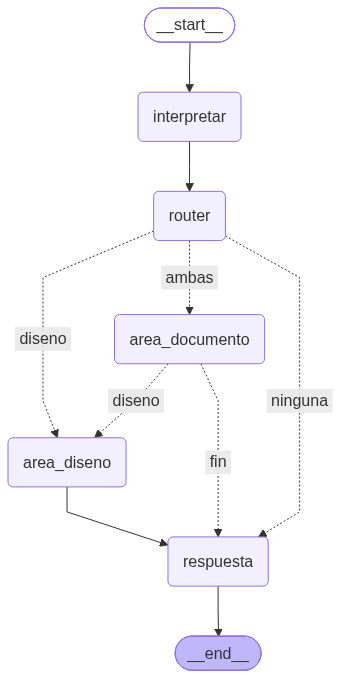

Supervisor


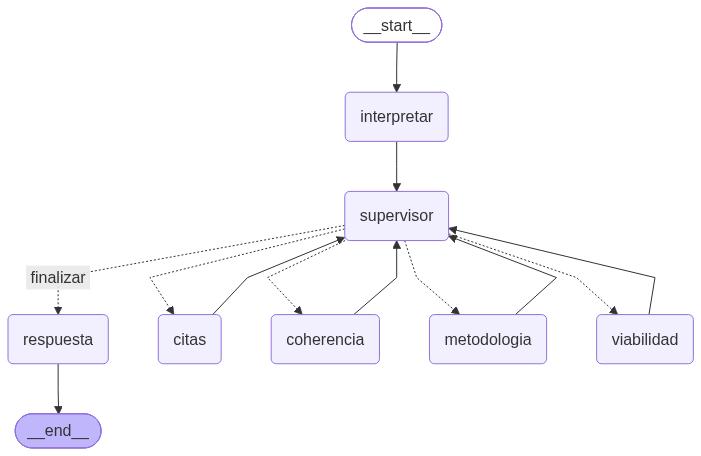

Jerárquica


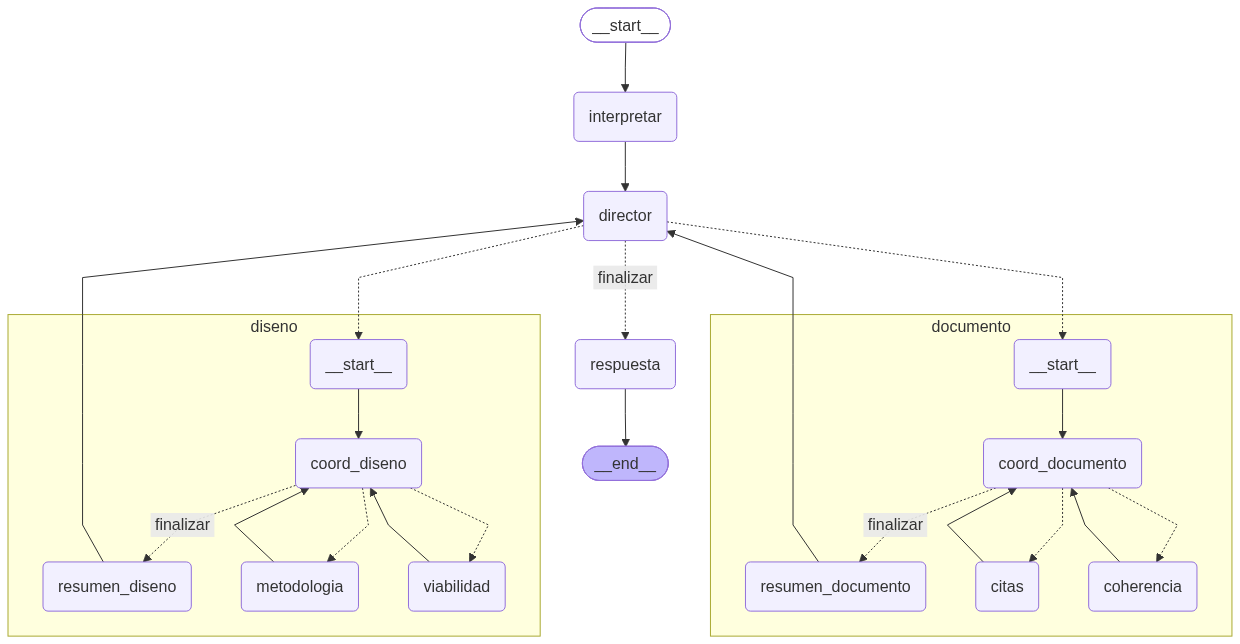

In [12]:
from IPython.display import display, Image

for a in ['Router', 'Supervisor', 'Jerárquica']:
    print(a)
    g = crear_grafo(a).get_graph(xray=True)      # xray=True: muestra también el interior de los subgrafos
    try:
        display(Image(g.draw_mermaid_png()))     # dibujo como imagen (usa un servicio web)
    except Exception:
        print(g.draw_mermaid())                  # si falla, texto Mermaid para pegar en mermaid.live

## Paso 12 · ▶️ Probar una solicitud sin interfaz
Ejecuta una solicitud y muestra la **bitácora**: quién le habló a quién. Cambia `ARQUITECTURA` y `SOLICITUD` para comparar.

In [13]:
import pandas as pd

# ── Cambia estas dos variables para comparar ──
ARQUITECTURA = 'Supervisor'      # 'Router' · 'Supervisor' · 'Jerárquica'
SOLICITUD = 'Prepara la entrega: revisa citas, coherencia, metodología y viabilidad'

# Los valores (en Gradio vienen de los controles numéricos)
PARAMETROS = {'n_muestras': 50, 'pliegues': 5, 'paginas': 14, 'horas_computo': 90, 'horas_disponibles': 120}

# Estado inicial: el "expediente" vacío con la solicitud
inicial = {'solicitud': SOLICITUD, 'parametros': PARAMETROS, 'objetivos': [], 'resultados': {}, 'bitacora': [], 'decisiones': 0}

# invoke() ejecuta TODO el grafo y devuelve solo el estado final
# recursion_limit: máximo de pasos permitidos (otro freno anti-ciclos)
final = crear_grafo(ARQUITECTURA).invoke(inicial, config={'recursion_limit': 50})

# Mostramos la bitácora como tabla: quién le habló a quién
tabla = pd.DataFrame([{'paso': m['paso'],
                       'de':   NOMBRES.get(m['emisor'], m['emisor']),
                       'para': NOMBRES.get(m['destinatario'], m['destinatario']),
                       'mensaje': m['contenido']}
                      for m in final['bitacora']])
with pd.option_context('display.max_colwidth', 120):
    display(tabla)

print(final['respuesta'])

,paso,de,para,mensaje
0,1,Recepción,Coordinación,"Prepara la entrega revisando citas, coherencia, metodología y viabilidad"
1,2,Orquestador,Verificador de citas,Iniciar la revisión de las citas para asegurar que todas las referencias estén correctas y completas antes de avanza...
2,3,Verificador de citas,Orquestador,"Se detectan citas sin referencia (REF-08), falta ficha de lectura (REF-05) y solo fichas de metadatos para REF-03 y ..."
3,4,Orquestador,Auditor de coherencia,Se ha completado la revisión de citas; el siguiente paso lógico es asegurar la coherencia del documento antes de ava...
4,5,Auditor de coherencia,Orquestador,Se detecta ausencia de actividades para OE3 en la metodología y falta de asignación de semanas para A4 en el cronogr...
5,6,Orquestador,Auditor metodológico,Se ha completado la revisión de citas y coherencia; ahora corresponde avanzar a la revisión de la metodología para a...
6,7,Auditor metodológico,Orquestador,"Se detecta falta de unidad en la variable respuesta ""calidad global"", impidiendo su medición adecuada; es un error g..."
7,8,Orquestador,Crítico de viabilidad,La viabilidad aún no ha sido revisada y es necesaria para completar la entrega del anteproyecto.
8,9,Crítico de viabilidad,Orquestador,Se detectó un hallazgo BLOQUEANTE: el tamaño 60 supera el entrenamiento máximo permitido de 40 muestras.
9,10,Orquestador,Respuesta a los proponentes,"Todas las revisiones solicitadas (citas, coherencia, metodología y viabilidad) han sido completadas."


Citas: 8 en el texto y 7 entradas en la bibliografía.

Coherencia: 3 objetivos específicos y 4 actividades revisadas.

Metodología: baseline «PLS-R sin aumento de datos»; métricas RMSEP, R2.

Viabilidad: entrenamiento máximo de 40 muestras; cómputo de 90 h de 120 h disponibles; 14 páginas.

Hallazgos:
- BLOQUEANTE · Verificador de citas: REF-08 se cita, pero no está en la bibliografía
- BLOQUEANTE · Crítico de viabilidad: El tamaño 60 supera el entrenamiento máximo (40 muestras)
- GRAVE · Verificador de citas: REF-05 no tiene ficha de lectura
- GRAVE · Auditor de coherencia: OE3 no tiene actividades en la metodología
- GRAVE · Auditor de coherencia: A4 no tiene semanas en el cronograma
- GRAVE · Auditor metodológico: La variable respuesta «calidad global» no tiene unidad: así no es medible
- AVISO · Verificador de citas: REF-03 solo tiene ficha de metadatos
- AVISO · Verificador de citas: REF-07 solo tiene ficha de metadatos

No está listo para enviar al director: 2 hallazgo(s) bloquea

## Paso 13 · ▶️ Construir la interfaz Gradio
El callback `atender` recorre el grafo con `stream(..., stream_mode='custom', subgraphs=True)` y, en cada aviso de inicio o fin, **redibuja** la interfaz con `yield`. Por eso en Jerárquica aparecen los coordinadores internos.

| Zona | Qué muestra |
|---|---|
| Tarjetas | Quién intervino; **azul** = trabajando ahora |
| Mensajes | Emisor → Destinatario: quién delega y quién recibe |
| Resultados | Los hallazgos de las herramientas |
| Respuesta | Texto final armado con esos hallazgos |

In [14]:
import gradio as gr


def tarjetas(bitacora, actual='', trabajando=False):
    """Genera el HTML de las tarjetas: una por cada participante que ha intervenido.
       La del nodo que está trabajando AHORA se pinta azul.
       Usamos colores fijos para que se lea igual en tema claro y oscuro."""
    # Participantes en orden de aparición, sin repetir (+ el que está trabajando ahora)
    nombres = list(dict.fromkeys([m['emisor'] for m in bitacora] + ([actual] if actual else [])))
    html = ''
    for n in nombres:
        activo = (n == actual and trabajando)
        html += (f'<div style="border:2px solid {"#2563eb" if activo else "#cbd5e1"};background:{"#dbeafe" if activo else "#f1f5f9"};'
                 f'padding:10px;border-radius:8px;color:#0f172a">'
                 f'<b style="color:#0f172a">{NOMBRES.get(n, n)}</b><br>'
                 f'<span style="color:#334155">{"Trabajando…" if activo else "Intervino"}</span></div>')
    return ('<div style="background:#ffffff;border-radius:12px;padding:12px;display:flex;gap:8px;flex-wrap:wrap">'
            + (html or '<span style="color:#64748b">Sin actividad</span>') + '</div>')


def atender(solicitud, arquitectura, n_muestras, pliegues, paginas, horas_computo, horas_disponibles):
    """Lo que pasa al hacer clic en 'Revisar anteproyecto'.
       Es un GENERADOR: cada `yield` redibuja la interfaz, así vemos el avance en vivo."""

    # 1) Parámetros desde los controles numéricos (enteros)
    p = {'n_muestras': int(n_muestras), 'pliegues': int(pliegues), 'paginas': int(paginas),
         'horas_computo': int(horas_computo), 'horas_disponibles': int(horas_disponibles)}

    # 2) Estado inicial. Lo iremos actualizando con lo que devuelva cada nodo
    e = {'solicitud': solicitud, 'parametros': p, 'objetivos': [], 'resultados': {}, 'bitacora': [], 'decisiones': 0}

    def vista(actual='', trabajando=False, estado=''):
        # Devuelve los 5 valores de salida en el MISMO orden que los outputs del botón:
        # [actividad, mensajes, resultados, salida, estado]
        filas = [[m['paso'], NOMBRES.get(m['emisor'], m['emisor']),
                  NOMBRES.get(m['destinatario'], m['destinatario']), m['contenido']] for m in e['bitacora']]
        return tarjetas(e['bitacora'], actual, trabajando), filas, e['resultados'], e.get('respuesta', ''), estado

    yield vista(estado='Iniciando ' + arquitectura + '…')       # primer dibujo: vacío

    try:
        grafo = crear_grafo(arquitectura)
        # stream(): ejecuta el grafo y nos entrega cada aviso del "megáfono" (get_stream_writer)
        #   stream_mode='custom' → solo los avisos de observable()
        #   subgraphs=True       → incluye avisos de nodos dentro de subgrafos (coordinadores)
        for _, aviso in grafo.stream(e, stream_mode='custom', subgraphs=True, config={'recursion_limit': 50}):
            if aviso['tipo'] == 'fin':
                e.update(aviso['salida'])                # guardamos lo que devolvió el nodo
            # Redibujamos: si es 'inicio', la tarjeta de ese nodo se pinta azul
            yield vista(aviso['nodo'], aviso['tipo'] == 'inicio', NOMBRES.get(aviso['nodo'], aviso['nodo']))
    except Exception as error:
        # Cualquier error (contrato inválido, opción no permitida, límite...) detiene la solicitud
        yield vista(estado=f'⛔ Detenido: {error}')
        return

    yield vista(estado=f'✅ {arquitectura}: terminado')


# ═══════════════════════════════════════════════════════════════════
# La interfaz: los componentes se dibujan en el orden en que se crean
# ═══════════════════════════════════════════════════════════════════
with gr.Blocks(title='Oficina del anteproyecto multiagente') as demo:
    gr.Markdown('# 🎓 La oficina del anteproyecto multiagente\nMismo anteproyecto y herramientas; cambia **quién decide**. Todo es ficticio.')

    # --- Entradas ---
    arquitectura = gr.Radio(['Router', 'Supervisor', 'Jerárquica'], value='Router', label='Arquitectura')
    solicitud = gr.Textbox(value='¿Las citas están completas?', label='Solicitud de los proponentes')
    gr.Examples([['¿Las citas están completas?'], ['Revisa la coherencia entre objetivos y cronograma'],
                 ['¿El diseño se puede ejecutar con las muestras que tenemos?'],
                 ['Prepara la entrega: revisa citas, coherencia, metodología y viabilidad'],
                 ['Redacta el numeral de antecedentes por mí']], inputs=solicitud)   # clic en un ejemplo = lo copia en la caja
    with gr.Row():      # los controles numéricos en una fila
        n_muestras = gr.Number(50, precision=0, label='Muestras')
        pliegues = gr.Number(5, precision=0, label='Pliegues de validación')
        paginas = gr.Number(14, precision=0, label='Páginas')
        horas_computo = gr.Number(90, precision=0, label='Horas de cómputo')
        horas_disponibles = gr.Number(120, precision=0, label='Horas disponibles')
    boton = gr.Button('Revisar anteproyecto', variant='primary')

    # --- Salidas ---
    estado = gr.Markdown('Lista para comenzar')                 # línea de estado
    actividad = gr.HTML()                                       # tarjetas
    mensajes = gr.Dataframe(headers=['Paso', 'Emisor', 'Destinatario', 'Mensaje'], wrap=True,
                            interactive=False, label='Mensajes entre participantes')
    with gr.Row():
        resultados = gr.JSON(label='Resultados de herramientas')
        salida = gr.Textbox(label='Respuesta a los proponentes', lines=12)

    # --- Conexión: al hacer clic, se llama a atender(entradas) y se actualizan las salidas ---
    boton.click(atender,
                [solicitud, arquitectura, n_muestras, pliegues, paginas, horas_computo, horas_disponibles],   # entradas (en orden)
                [actividad, mensajes, resultados, salida, estado])                                           # salidas (mismo orden que vista())

print('Interfaz construida. Ejecuta el paso 14 para abrirla.')

c:\Users\A47x\OneDrive\A47x\ARQUITECTURAS-EN-INTELIGENCIA-ARTIFICIAL-MULTIAGENTICA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Interfaz construida. Ejecuta el paso 14 para abrirla.


## Paso 14 · ▶️ Abrir la interfaz
En Colab, `share=True` crea un enlace público temporal (solo datos ficticios). En local no se comparte: la interfaz se abre en `http://127.0.0.1:7860` (o el siguiente puerto libre) y solo es accesible desde tu equipo, así nadie más puede usar tu clave de Groq a través del enlace. `debug=False` deja la celda libre para seguir usando el notebook.

In [15]:
# ¿Estamos en Colab? (el módulo google.colab solo existe allí)
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# share=EN_COLAB → en Colab crea además un enlace público temporal (solo datos ficticios);
#                  en tu PC la interfaz solo se abre en tu equipo (http://127.0.0.1:7860)
# debug=False    → la celda termina y puedes seguir ejecutando otras celdas
demo.launch(share=EN_COLAB, debug=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## Paso 15 · ▶️ Cerrar la interfaz
Ejecútala al terminar, o antes de reconstruir la interfaz (paso 13) si cambiaste código.

In [16]:
# Apaga el servidor de Gradio (libera el puerto y el enlace público)
demo.close()

Closing server running on port: 7860


## Paso 16 · Recorrido guiado y ejercicio

### Recorrido guiado (en la interfaz)
| # | Arquitectura y solicitud | Qué observar |
|---|---|---|
| 1 | **Router** · «¿Las citas están completas?» | Una clasificación inicial y la intervención del Verificador de citas |
| 2 | **Supervisor** · misma solicitud | El Verificador **devuelve** el control al Orquestador, que decide finalizar |
| 3 | **Jerárquica** · misma solicitud | Director → Coordinador de Documento → Citas → Coordinador → Resumen → Director. Más pasos, **mismos hallazgos** |
| 4 | Las tres · «Prepara la entrega…» | Compara rutas sin cambiar controles |
| 5 | Resultados | 2 bloqueantes (`REF-08` sin entrada y el tamaño 60), 4 graves y 2 avisos |
| 6 | Cualquiera · «¿El diseño se puede ejecutar…?» con **75 muestras** | El entrenamiento máximo sube a 60 y el bloqueante de viabilidad desaparece |
| 7 | Cualquiera · «Redacta el numeral de antecedentes por mí» | Responde qué puede revisar; **no** redacta ni inventa un especialista nuevo |

> 🤖 Como decide un LLM, **el orden** de los especialistas puede variar entre ejecuciones. **Los hallazgos no cambian**: los calcula Python.

### Ejercicio
Sigue **`05b_Ejercicio_Oficina_Anteproyecto.md`**: predice, ejecuta, registra la traza de la revisión completa, cambia el número de muestras, agrega un quinto especialista (`jurado-simulado`) y escribe un ADR breve. El reto es implementar una cuarta arquitectura: la **secuencial con paradas** que usa cacaoia-utp en su revisión completa.

### Diferencias con el sistema real
| cacaoia-utp | Este notebook |
|---|---|
| Cada agente es un subagente de Claude Code que **lee los archivos** del anteproyecto | Cada especialista es una herramienta de Python sobre un diccionario ficticio + una explicación del LLM |
| El orquestador decide con una tabla de situaciones (qué se tocó → qué agente) | El Orquestador elige entre las revisiones pedidas que siguen pendientes |
| La revisión completa corre los auditores **en un orden fijo** y **se detiene** ante un bloqueante | Ninguna de las tres arquitecturas se detiene por severidad (es el reto) |

### ⚠️ Errores frecuentes
| Síntoma | Causa | Qué hacer |
|---|---|---|
| `GROQ_API_KEY` vacía / error 401 | No está en `.env` (local) o en Secrets, o falta dar acceso al notebook | Local: agrégala a `.env` · Colab: 🔑 Secrets → agregar `GROQ_API_KEY` y activar el acceso |
| La interfaz no se ve dentro de VS Code | El visor del notebook no muestra la vista incrustada | Abre en el navegador la URL local que imprime el paso 14 (`http://127.0.0.1:7860`) |
| Error 429 (rate limit) | Muchas llamadas seguidas | Espera unos segundos y repite |
| `ValidationError` de Pydantic | El LLM devolvió un JSON que no cumple el contrato | Vuelve a intentar; es el contrato funcionando |
| `⛔ Detenido: … al menos 2 pliegues` | Pliegues en 0 o 1 | La validación cruzada necesita k ≥ 2 |
| Cambié las muestras en la frase y no cambió el resultado | Los valores vienen de los **controles** | Cambia los campos numéricos |
| La interfaz no refleja cambios de código | Sigue abierta la versión anterior | Paso 15 → re-ejecutar → 13 → 14 |